# Employee Attrition Risk and Workforce Insights Using Data Analytics and Machine Learning

**Domain:** Human Resources (HR) Analytics  
**Student:** Parth Lakhan | **Course:** TY B.Sc. IT  
**Program:** IBM SkillsBuild Data Analytics with AI Academic Internship Program (BharatCares, in association with AICTE)

---

## 1. Project Title and Overview

Employee attrition (employees leaving an organization) increases recruitment and training costs, disrupts teams and removes experienced people. This notebook analyses an employee dataset to:

1. understand the workforce and measure attrition,
2. find groups and conditions associated with higher attrition,
3. build and evaluate a machine-learning classification model, and
4. translate the results into practical, evidence-based recommendations for HR decision-makers.

The analysis follows the business intelligence sequence used throughout this notebook:

**Data → Information → Insights → Decisions → Actions**

| Stage | Meaning in this project |
|---|---|
| **Data** | Raw employee records (1 row per employee) |
| **Information** | Cleaned data, KPIs, attrition rates, charts |
| **Insights** | What the patterns may mean for the workforce |
| **Decisions** | What HR could decide to investigate or change |
| **Actions** | Specific, realistic steps with supporting evidence |

## 2. Business Problem Statement

Employee attrition can increase recruitment costs, disrupt teams, and cause organizations to lose experienced employees. Organizations need to understand workforce patterns, identify employee groups with higher attrition, and use data to guide retention strategies.

**Main objective:** convert raw employee data into useful information, insights, risks, opportunities and recommended business actions.

## 3. Objectives and Scope

**Objectives**

1. Inspect, validate and clean the employee dataset.
2. Calculate attrition KPIs overall and by department, job role, overtime, tenure, age group and satisfaction measures.
3. Visualize attrition patterns with clear, decision-oriented charts.
4. Build a baseline and machine-learning classification models to estimate attrition risk, and evaluate them with appropriate metrics (not accuracy alone).
5. Present a dashboard-style summary and practical recommendations.

**In scope:** descriptive analytics, exploratory analysis and a supervised binary classification model on a public, historical, fictional dataset.

**Out of scope:** causal proof, financial cost modelling, real-time prediction, and any automated employment decision-making. The model is exploratory only.

## 4. Dataset Source and Description

* **Dataset:** IBM HR Analytics Employee Attrition & Performance
* **Source:** Kaggle - https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset
* **Expected file name:** `WA_Fn-UseC_-HR-Employee-Attrition.csv`
* **Nature of data:** a fictional dataset created by IBM data scientists for learning and demonstration; it is **not** real employee data.
* **Target variable:** `Attrition` (`Yes` = employee left, `No` = employee stayed)

The file contains employee demographics (age, gender, marital status), job information (department, role, level, overtime, business travel), compensation (monthly income, salary hike, stock option level), satisfaction ratings (job, environment, relationship, work-life balance) and career history (years at company, years since last promotion, etc.). Column meanings are checked after loading in Section 7.

## 5. Importing Libraries

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)

warnings.filterwarnings("ignore", category=FutureWarning)

# Consistent look for all charts
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.labelsize": 10})
C_STAY, C_LEFT, C_MAIN = "#4C72B0", "#C44E52", "#55A868"   # colour scheme used everywhere
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
print("Libraries imported successfully.")

Libraries imported successfully.


## 6. Loading the CSV Dataset

The notebook does **not** need Kaggle credentials. Download the CSV manually from the Kaggle link above and place it in the **same folder as this notebook** (or in a sub-folder named `data`). The cell below searches for the file and stops with a clear message if it is missing.

In [2]:
CSV_NAME = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
SEARCH_PATHS = [Path(CSV_NAME), Path("data") / CSV_NAME]

csv_path = next((p for p in SEARCH_PATHS if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        f"Dataset file '{CSV_NAME}' was not found.\n"
        "1. Open https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset\n"
        "2. Click Download and extract the ZIP file.\n"
        f"3. Copy '{CSV_NAME}' into the same folder as this notebook: {Path.cwd()}\n"
        "4. Re-run this cell."
    )

# utf-8-sig safely removes an invisible byte-order mark if one is present in the file
df_raw = pd.read_csv(csv_path, encoding="utf-8-sig")
df_raw.columns = df_raw.columns.str.strip()

REQUIRED_COLUMNS = {"Attrition", "Department", "JobRole", "OverTime", "Age", "MonthlyIncome",
                    "YearsAtCompany", "JobSatisfaction", "EmployeeNumber"}
missing_cols = REQUIRED_COLUMNS - set(df_raw.columns)
if missing_cols:
    raise ValueError(f"The CSV is missing expected columns: {sorted(missing_cols)}. "
                     "Please use the original Kaggle file.")

print(f"Loaded '{csv_path}' successfully: {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")

Loaded 'WA_Fn-UseC_-HR-Employee-Attrition.csv' successfully: 1470 rows x 35 columns


## 7. Initial Data Inspection

In [3]:
print("Shape (rows, columns):", df_raw.shape)
print("\nColumn names:")
print(list(df_raw.columns))

Shape (rows, columns): (1470, 35)

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [4]:
display(df_raw.dtypes.rename("Data type").to_frame())

,Data type
Age,int64
Attrition,str
BusinessTravel,str
DailyRate,int64
Department,str
DistanceFromHome,int64
Education,int64
EducationField,str
EmployeeCount,int64
EmployeeNumber,int64


In [5]:
display(df_raw.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.92,9.14,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.49,403.51,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.19,8.11,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.91,1.02,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.87,602.02,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.72,1.09,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.89,20.33,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.73,0.71,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.06,1.11,1.0,1.00,2.0,3.00,5.0


In [6]:
display(df_raw.describe(exclude="number").T)

,count,unique,top,freq
Attrition,1470,2,No,1233
BusinessTravel,1470,3,Travel_Rarely,1043
Department,1470,3,Research & Development,961
EducationField,1470,6,Life Sciences,606
Gender,1470,2,Male,882
JobRole,1470,9,Sales Executive,326
MaritalStatus,1470,3,Married,673
Over18,1470,1,Y,1470
OverTime,1470,2,No,1054


In [7]:
display(df_raw.head())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


**Reading the output.** Each row is one employee. Numeric columns such as `Education`, `JobSatisfaction`, `EnvironmentSatisfaction`, `JobInvolvement`, `WorkLifeBalance`, `PerformanceRating` and `StockOptionLevel` are *coded ratings/levels* (for example 1 = Low ... 4 = Very High), not continuous measurements, so averages of them are interpreted as rating scores.

## 8. Data Quality Checks

In [8]:
# 8.1 Missing values
missing = df_raw.isna().sum()
print("Total missing cells:", int(missing.sum()))
display(missing[missing > 0].to_frame("Missing") if missing.sum() else pd.DataFrame({"Result": ["No missing values found"]}))

# 8.2 Duplicate records
print("Fully duplicated rows:", int(df_raw.duplicated().sum()))
print("Duplicated EmployeeNumber values:", int(df_raw["EmployeeNumber"].duplicated().sum()))

# 8.3 Data types: object (text) vs numeric columns
text_cols = df_raw.select_dtypes(exclude="number").columns.tolist()
num_cols_raw = df_raw.select_dtypes(include="number").columns.tolist()
print("\nText columns   :", text_cols)
print("Numeric columns:", len(num_cols_raw), "columns")

Total missing cells: 0


,Result
0,No missing values found


Fully duplicated rows: 0
Duplicated EmployeeNumber values: 0

Text columns   : ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']
Numeric columns: 26 columns


In [9]:
# 8.4 Inconsistent values: show the distinct values of every text column
for c in text_cols:
    print(f"{c:15s} -> {sorted(df_raw[c].unique())}")

# 8.5 Constant columns (carry no information) and sanity/range checks
constant_cols = [c for c in df_raw.columns if df_raw[c].nunique() == 1]
print("\nConstant columns (single value):", constant_cols)

checks = {
    "Age below 18": int((df_raw["Age"] < 18).sum()),
    "Negative MonthlyIncome": int((df_raw["MonthlyIncome"] <= 0).sum()),
    "YearsAtCompany > TotalWorkingYears": int((df_raw["YearsAtCompany"] > df_raw["TotalWorkingYears"]).sum()),
    "YearsInCurrentRole > YearsAtCompany": int((df_raw["YearsInCurrentRole"] > df_raw["YearsAtCompany"]).sum()),
    "Attrition values other than Yes/No": int((~df_raw["Attrition"].isin(["Yes", "No"])).sum()),
}
display(pd.Series(checks, name="Records failing check").to_frame())

Attrition       -> ['No', 'Yes']
BusinessTravel  -> ['Non-Travel', 'Travel_Frequently', 'Travel_Rarely']
Department      -> ['Human Resources', 'Research & Development', 'Sales']
EducationField  -> ['Human Resources', 'Life Sciences', 'Marketing', 'Medical', 'Other', 'Technical Degree']
Gender          -> ['Female', 'Male']
JobRole         -> ['Healthcare Representative', 'Human Resources', 'Laboratory Technician', 'Manager', 'Manufacturing Director', 'Research Director', 'Research Scientist', 'Sales Executive', 'Sales Representative']
MaritalStatus   -> ['Divorced', 'Married', 'Single']
Over18          -> ['Y']
OverTime        -> ['No', 'Yes']

Constant columns (single value): ['EmployeeCount', 'Over18', 'StandardHours']


,Records failing check
Age below 18,0
Negative MonthlyIncome,0
YearsAtCompany > TotalWorkingYears,0
YearsInCurrentRole > YearsAtCompany,0
Attrition values other than Yes/No,0


**Data quality summary.** The checks above show whether the data needs repair. Where the counts are zero, no correction is required; any constant columns are removed in the next section because they contain no information. Nothing is imputed or invented.

## 9. Data Cleaning and Preparation

Changes made (each is explained so the process is transparent):

| Step | Why |
|---|---|
| Remove constant columns (single value for all rows) | They cannot help explain or predict attrition |
| Keep `EmployeeNumber` only as an identifier (excluded from modelling later) | Identifiers carry no behavioural meaning and can cause spurious patterns |
| Create `Attrition_Flag` (1 = left, 0 = stayed) | Numeric target needed for rates and modelling |
| Create `AgeGroup`, `TenureGroup`, `IncomeBand` | Easier-to-read business groupings for EDA |
| Add readable labels for coded 1-4 rating scales (only for charts) | Charts become easier to understand |

The original `df_raw` is kept untouched; all changes are made on a copy named `df`.

In [10]:
df = df_raw.copy()

# 1. Drop constant columns
df = df.drop(columns=constant_cols)

# 2. Numeric target
df["Attrition_Flag"] = (df["Attrition"] == "Yes").astype(int)

# 3. Business groupings
df["AgeGroup"] = pd.cut(df["Age"], bins=[17, 25, 35, 45, 55, 100],
                        labels=["18-25", "26-35", "36-45", "46-55", "56+"])
df["TenureGroup"] = pd.cut(df["YearsAtCompany"], bins=[-1, 1, 5, 10, 20, 100],
                           labels=["0-1 yr", "2-5 yrs", "6-10 yrs", "11-20 yrs", "20+ yrs"])
df["IncomeBand"] = pd.qcut(df["MonthlyIncome"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])

# 4. Labels for the 1-4 rating scales (used for readable charts only)
SAT_LABELS = {1: "1-Low", 2: "2-Medium", 3: "3-High", 4: "4-Very High"}
WLB_LABELS = {1: "1-Bad", 2: "2-Good", 3: "3-Better", 4: "4-Best"}

print("Shape before:", df_raw.shape, "| after:", df.shape)
print("Columns removed:", constant_cols)
display(df[["Age", "AgeGroup", "YearsAtCompany", "TenureGroup", "MonthlyIncome", "IncomeBand", "Attrition", "Attrition_Flag"]].head())

Shape before: (1470, 35) | after: (1470, 36)
Columns removed: ['EmployeeCount', 'Over18', 'StandardHours']


,Age,AgeGroup,YearsAtCompany,TenureGroup,MonthlyIncome,IncomeBand,Attrition,Attrition_Flag
0,41,36-45,6,6-10 yrs,5993,Q3,Yes,1
1,49,46-55,10,6-10 yrs,5130,Q3,No,0
2,37,36-45,0,0-1 yr,2090,Q1 (lowest),Yes,1
3,33,26-35,8,6-10 yrs,2909,Q1 (lowest),No,0
4,27,26-35,2,2-5 yrs,3468,Q2,No,0


## 10. Exploratory Data Analysis (EDA)

We first describe the workforce, then compare employees who left with those who stayed. A small helper function creates a consistent *attrition-rate table* for any grouping column. Groups with fewer than 30 employees are flagged because their rates are unstable.

In [11]:
def attrition_table(data, col, sort_by_rate=False):
    """Employees, leavers and attrition rate (%) for each value of `col`."""
    t = (data.groupby(col, observed=False)["Attrition_Flag"]
             .agg(Employees="count", Left="sum")
             .assign(Attrition_Rate_pct=lambda x: (x["Left"] / x["Employees"] * 100).round(1)))
    t["Small_group(<30)"] = np.where(t["Employees"] < 30, "yes", "")
    return t.sort_values("Attrition_Rate_pct", ascending=False) if sort_by_rate else t

print("Workforce profile")
profile = pd.DataFrame({
    "Average age": [df["Age"].mean()],
    "Average monthly income": [df["MonthlyIncome"].mean()],
    "Average years at company": [df["YearsAtCompany"].mean()],
    "Average total working years": [df["TotalWorkingYears"].mean()],
    "Average distance from home": [df["DistanceFromHome"].mean()],
}).round(1)
display(profile)

Workforce profile


,Average age,Average monthly income,Average years at company,Average total working years,Average distance from home
0,36.9,6502.9,7.0,11.3,9.2


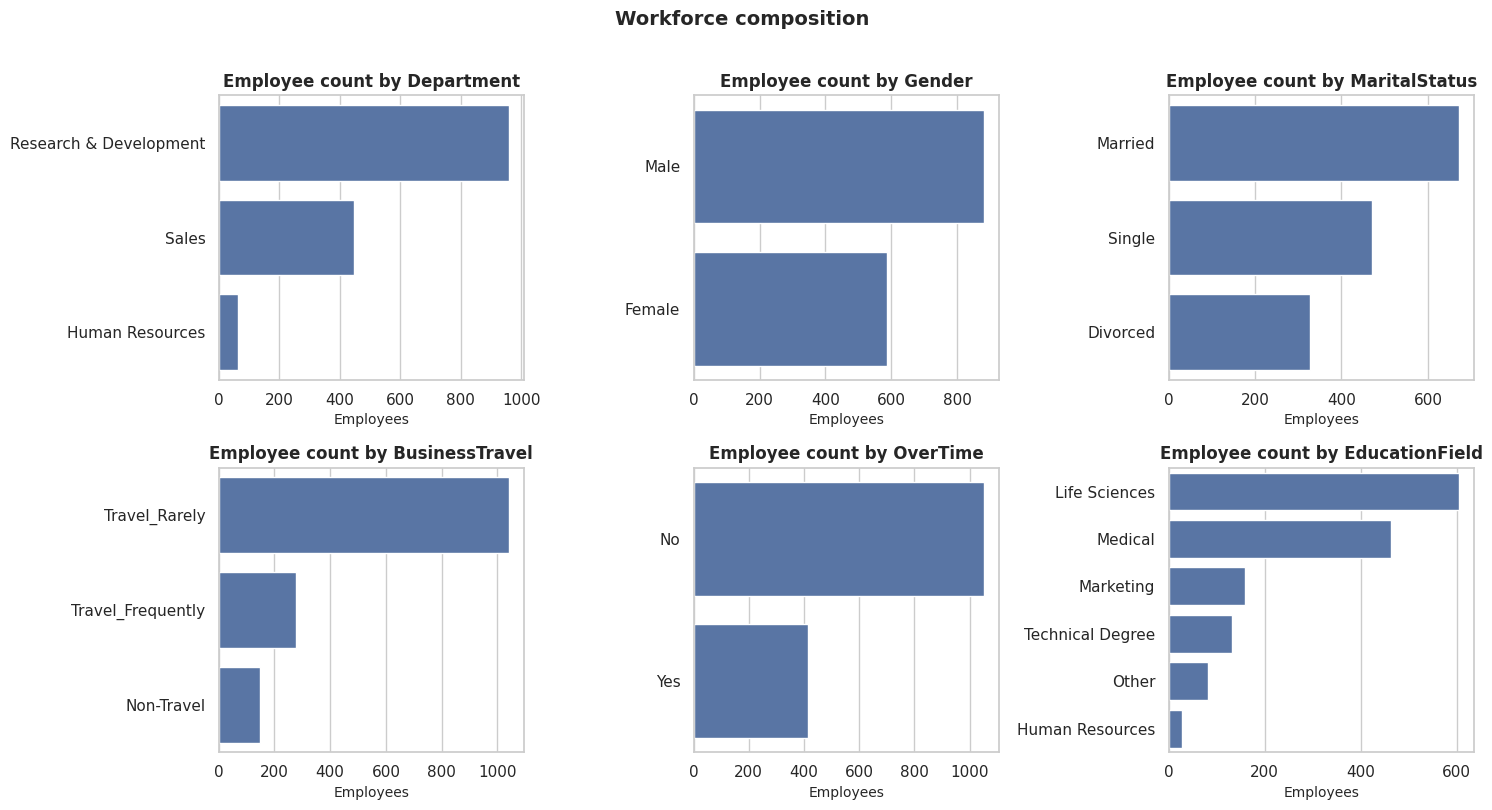

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["Department", "Gender", "MaritalStatus", "BusinessTravel", "OverTime", "EducationField"]):
    order = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=order, color=C_STAY, ax=ax)
    ax.set_title(f"Employee count by {col}")
    ax.set_xlabel("Employees"); ax.set_ylabel("")
plt.suptitle("Workforce composition", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

**What this chart tells us:** it describes *who* works in the organization (workforce mix). It matters because attrition counts mean little without knowing how large each group is - a department with many leavers may simply be a large department. We therefore use **attrition rates**, not raw counts, for comparisons.

In [13]:
num_summary = df.groupby("Attrition")[["Age", "MonthlyIncome", "YearsAtCompany", "YearsSinceLastPromotion",
                                       "DistanceFromHome", "TotalWorkingYears", "NumCompaniesWorked"]].mean().round(2).T
num_summary["Difference (Left - Stayed)"] = (num_summary["Yes"] - num_summary["No"]).round(2)
print("Average values: employees who stayed (No) vs left (Yes)")
display(num_summary)

Average values: employees who stayed (No) vs left (Yes)


Attrition,No,Yes,Difference (Left - Stayed)
Age,37.56,33.61,-3.95
MonthlyIncome,6832.74,4787.09,-2045.65
YearsAtCompany,7.37,5.13,-2.24
YearsSinceLastPromotion,2.23,1.95,-0.28
DistanceFromHome,8.92,10.63,1.71
TotalWorkingYears,11.86,8.24,-3.62
NumCompaniesWorked,2.65,2.94,0.29


## 11. Key Performance Indicators (KPIs)

KPIs below are calculated directly from the dataset.

In [14]:
total_emp = len(df)
left_emp = int(df["Attrition_Flag"].sum())
stayed_emp = total_emp - left_emp
overall_rate = left_emp / total_emp * 100

kpi = {
    "Total employee records": total_emp,
    "Employees who left (Attrition = Yes)": left_emp,
    "Employees who stayed": stayed_emp,
    "Overall attrition rate (%)": round(overall_rate, 1),
    "Average job satisfaction (1-4), all employees": round(df["JobSatisfaction"].mean(), 2),
    "Average job satisfaction - stayed": round(df.loc[df.Attrition == "No", "JobSatisfaction"].mean(), 2),
    "Average job satisfaction - left": round(df.loc[df.Attrition == "Yes", "JobSatisfaction"].mean(), 2),
    "Average environment satisfaction (1-4)": round(df["EnvironmentSatisfaction"].mean(), 2),
    "Average work-life balance (1-4)": round(df["WorkLifeBalance"].mean(), 2),
    "Average monthly income": round(df["MonthlyIncome"].mean(), 0),
    "Average years at company": round(df["YearsAtCompany"].mean(), 1),
    "Employees working overtime (%)": round((df["OverTime"] == "Yes").mean() * 100, 1),
}
display(pd.Series(kpi, name="Value").to_frame())

dept_tbl = attrition_table(df, "Department", sort_by_rate=True)
role_tbl = attrition_table(df, "JobRole", sort_by_rate=True)
ot_tbl = attrition_table(df, "OverTime", sort_by_rate=True)
print("\nAttrition by Department"); display(dept_tbl)
print("Attrition by Job Role");     display(role_tbl)
print("Attrition by OverTime");     display(ot_tbl)

,Value
Total employee records,1470.00
Employees who left (Attrition = Yes),237.00
Employees who stayed,1233.00
Overall attrition rate (%),16.10
"Average job satisfaction (1-4), all employees",2.73
Average job satisfaction - stayed,2.78
Average job satisfaction - left,2.47
Average environment satisfaction (1-4),2.72
Average work-life balance (1-4),2.76
Average monthly income,6503.00



Attrition by Department


,Employees,Left,Attrition_Rate_pct,Small_group(<30)
Department,,,,
Sales,446,92,20.6,
Human Resources,63,12,19.0,
Research & Development,961,133,13.8,


Attrition by Job Role


,Employees,Left,Attrition_Rate_pct,Small_group(<30)
JobRole,,,,
Sales Representative,83,33,39.8,
Laboratory Technician,259,62,23.9,
Human Resources,52,12,23.1,
Sales Executive,326,57,17.5,
Research Scientist,292,47,16.1,
Healthcare Representative,131,9,6.9,
Manufacturing Director,145,10,6.9,
Manager,102,5,4.9,
Research Director,80,2,2.5,


Attrition by OverTime


,Employees,Left,Attrition_Rate_pct,Small_group(<30)
OverTime,,,,
Yes,416,127,30.5,
No,1054,110,10.4,


In [15]:
print("Attrition by Age Group");     display(attrition_table(df, "AgeGroup"))
print("Attrition by Tenure Group");  display(attrition_table(df, "TenureGroup"))
print("Attrition by Income Band");   display(attrition_table(df, "IncomeBand"))

Attrition by Age Group


,Employees,Left,Attrition_Rate_pct,Small_group(<30)
AgeGroup,,,,
18-25,123,44,35.8,
26-35,606,116,19.1,
36-45,468,43,9.2,
46-55,226,26,11.5,
56+,47,8,17.0,


Attrition by Tenure Group


,Employees,Left,Attrition_Rate_pct,Small_group(<30)
TenureGroup,,,,
0-1 yr,215,75,34.9,
2-5 yrs,561,87,15.5,
6-10 yrs,448,55,12.3,
11-20 yrs,180,12,6.7,
20+ yrs,66,8,12.1,


Attrition by Income Band


,Employees,Left,Attrition_Rate_pct,Small_group(<30)
IncomeBand,,,,
Q1 (lowest),369,108,29.3,
Q2,366,52,14.2,
Q3,367,39,10.6,
Q4 (highest),368,38,10.3,


## 12. Visual Analysis of Attrition by Employee Attributes

Every chart below shows the **attrition rate (%)**, with the dashed line marking the company-wide rate so that above-average groups are easy to see. The number on each bar's label (`n=`) is the group size.

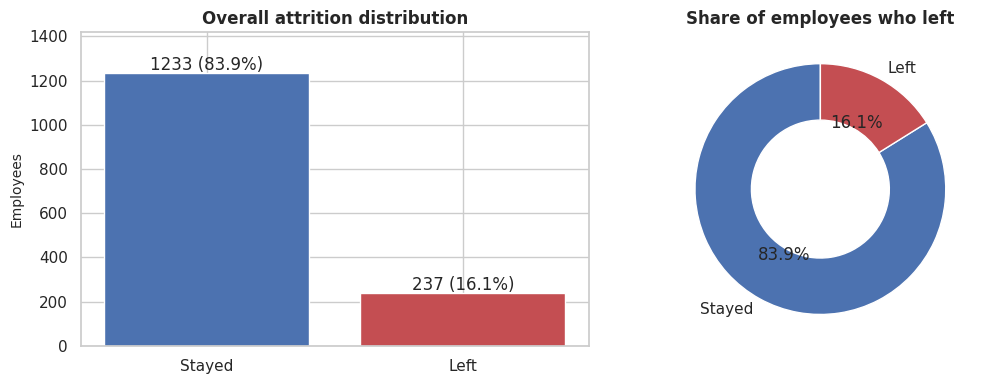

In [16]:
def rate_barplot(ax, table, title, horizontal=False, rotate=0):
    """Draw attrition-rate bars, highlight bars above the overall rate, annotate group sizes."""
    labels = table.index.astype(str)
    rates = table["Attrition_Rate_pct"].values
    colors = [C_LEFT if r > overall_rate else C_STAY for r in rates]
    if horizontal:
        bars = ax.barh(labels, rates, color=colors)
        ax.axvline(overall_rate, color="black", ls="--", lw=1)
        ax.invert_yaxis(); ax.set_xlabel("Attrition rate (%)")
        for b, r, n in zip(bars, rates, table["Employees"]):
            ax.text(r + 0.3, b.get_y() + b.get_height() / 2, f"{r:.1f}% (n={n})", va="center", fontsize=8)
        ax.set_xlim(0, max(rates) * 1.25)
    else:
        bars = ax.bar(labels, rates, color=colors)
        ax.axhline(overall_rate, color="black", ls="--", lw=1)
        ax.set_ylabel("Attrition rate (%)")
        for b, r, n in zip(bars, rates, table["Employees"]):
            ax.text(b.get_x() + b.get_width() / 2, r + 0.4, f"{r:.1f}%\nn={n}", ha="center", fontsize=8)
        ax.set_ylim(0, max(rates) * 1.3)
        plt.setp(ax.get_xticklabels(), rotation=rotate, ha="right" if rotate else "center")
    ax.set_title(title)

# Chart 1: overall distribution
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
counts = df["Attrition"].value_counts().reindex(["No", "Yes"])
ax[0].bar(["Stayed", "Left"], counts.values, color=[C_STAY, C_LEFT])
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 15, f"{v} ({v / total_emp * 100:.1f}%)", ha="center")
ax[0].set_title("Overall attrition distribution"); ax[0].set_ylabel("Employees"); ax[0].set_ylim(0, counts.max() * 1.15)
ax[1].pie(counts.values, labels=["Stayed", "Left"], colors=[C_STAY, C_LEFT], autopct="%1.1f%%", startangle=90,
          wedgeprops={"width": 0.45})
ax[1].set_title("Share of employees who left")
plt.tight_layout(); plt.show()

**What it tells us / why it matters:** the dataset is *imbalanced* - far fewer employees left than stayed. This sets the baseline attrition rate that every other group is compared against, and it affects how the machine-learning model must be trained and evaluated (Section 15-16).

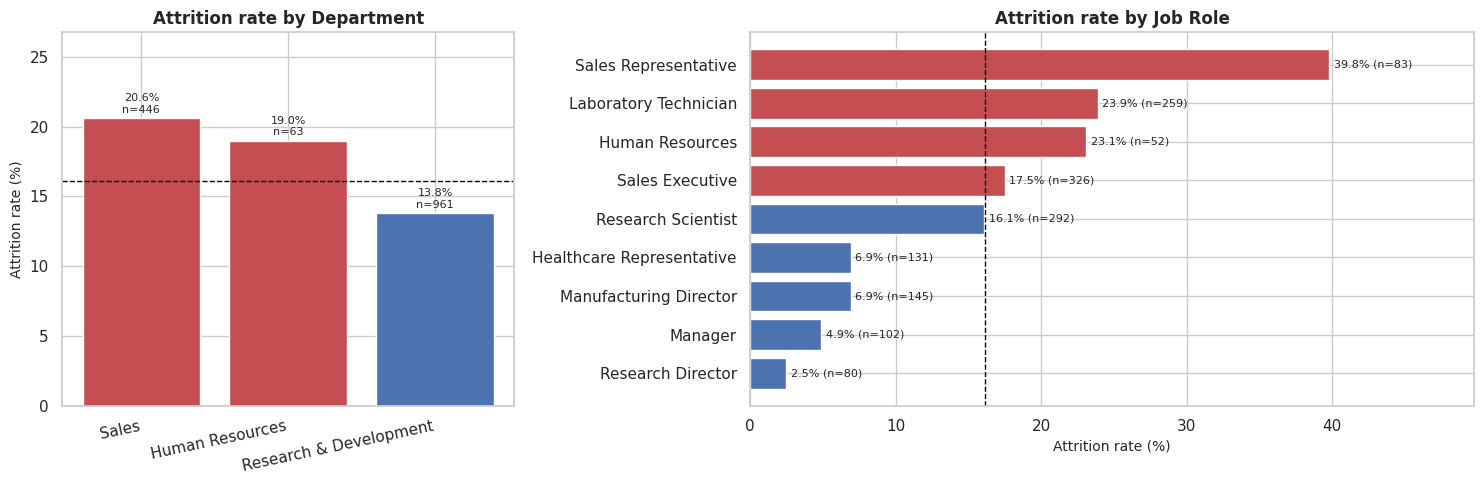

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.6]})
rate_barplot(axes[0], dept_tbl, "Attrition rate by Department", rotate=12)
rate_barplot(axes[1], role_tbl, "Attrition rate by Job Role", horizontal=True)
plt.tight_layout(); plt.show()

**What it tells us / why it matters:** it shows *where* attrition is concentrated. A high rate in a department or job role suggests that role-specific causes (workload, pay, career path, management) should be investigated first, which helps HR focus limited retention effort instead of applying one policy everywhere.

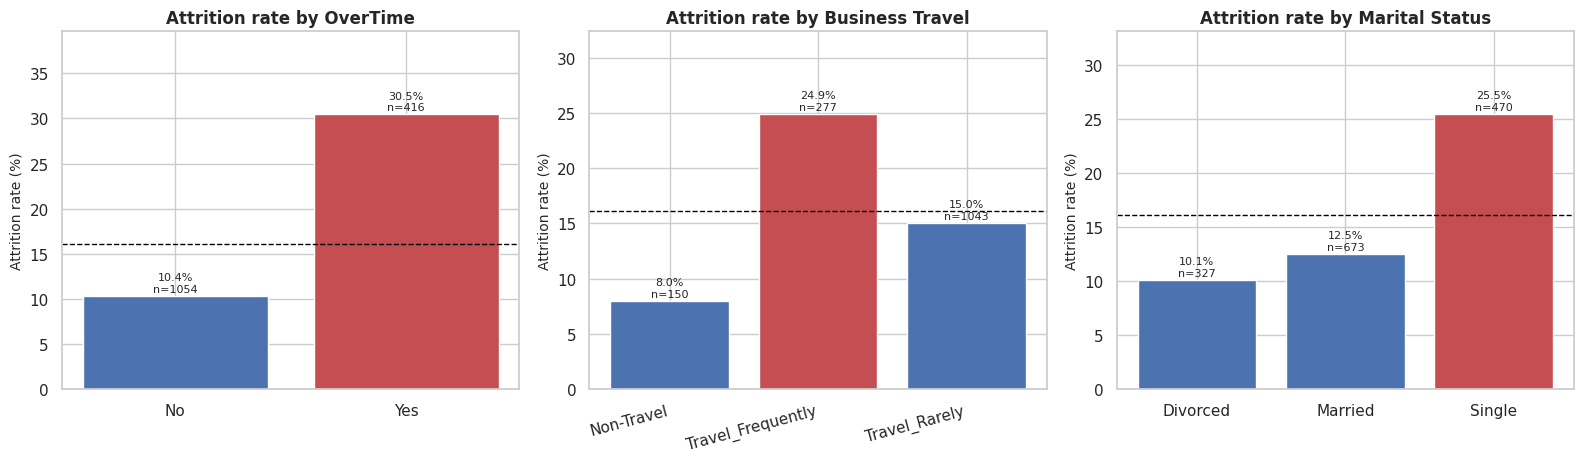

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
rate_barplot(axes[0], attrition_table(df, "OverTime"), "Attrition rate by OverTime")
rate_barplot(axes[1], attrition_table(df, "BusinessTravel"), "Attrition rate by Business Travel", rotate=15)
rate_barplot(axes[2], attrition_table(df, "MaritalStatus"), "Attrition rate by Marital Status")
plt.tight_layout(); plt.show()

**What it tells us / why it matters:** overtime and travel are *work-condition* factors that management can influence (unlike age or marital status). If employees working overtime leave at a clearly higher rate, workload planning becomes a practical retention lever.

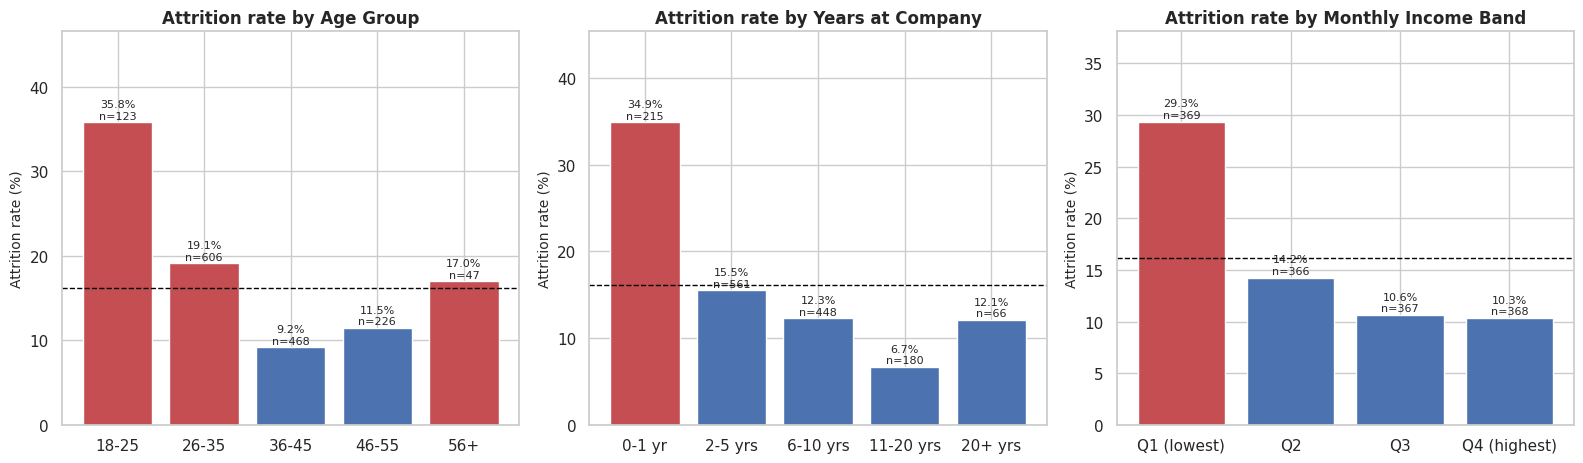

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
rate_barplot(axes[0], attrition_table(df, "AgeGroup"), "Attrition rate by Age Group")
rate_barplot(axes[1], attrition_table(df, "TenureGroup"), "Attrition rate by Years at Company")
rate_barplot(axes[2], attrition_table(df, "IncomeBand"), "Attrition rate by Monthly Income Band")
plt.tight_layout(); plt.show()

**What it tells us / why it matters:** age, tenure and income describe the employee life-cycle. They help HR decide *when* in an employee's journey retention effort (onboarding support, career conversations, pay reviews) is most needed.

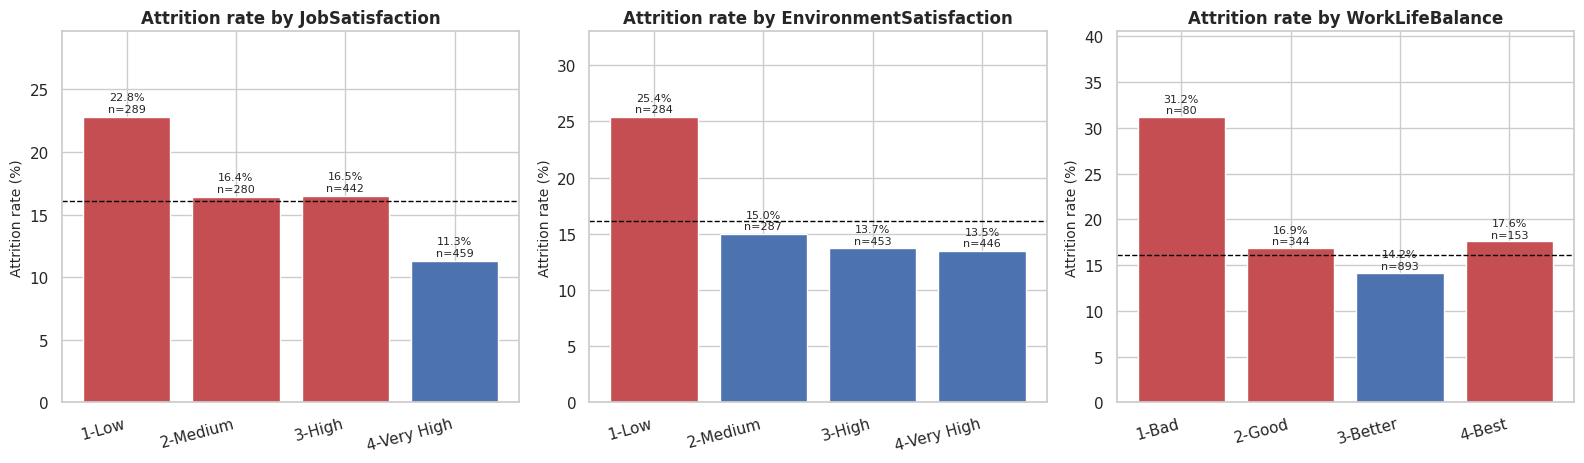

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, col, lab in zip(axes, ["JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance"],
                        [SAT_LABELS, SAT_LABELS, WLB_LABELS]):
    t = attrition_table(df, col)
    t.index = [lab[i] for i in t.index]
    rate_barplot(ax, t, f"Attrition rate by {col}", rotate=15)
plt.tight_layout(); plt.show()

**What it tells us / why it matters:** satisfaction ratings are early-warning signals. If lower ratings go together with higher attrition, regular pulse surveys can help HR notice at-risk teams before people resign.

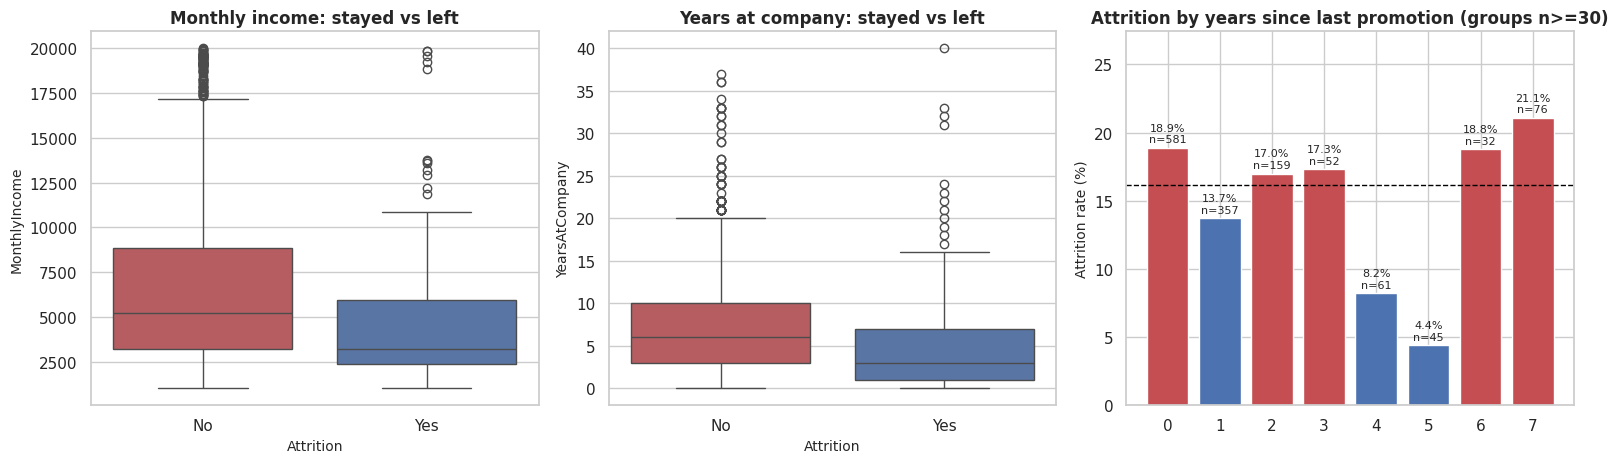

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sns.boxplot(data=df, x="Attrition", y="MonthlyIncome", order=["No", "Yes"], palette=[C_STAY, C_LEFT], hue="Attrition", legend=False, ax=axes[0])
axes[0].set_title("Monthly income: stayed vs left")
sns.boxplot(data=df, x="Attrition", y="YearsAtCompany", order=["No", "Yes"], palette=[C_STAY, C_LEFT], hue="Attrition", legend=False, ax=axes[1])
axes[1].set_title("Years at company: stayed vs left")
rate_barplot(axes[2], attrition_table(df, "YearsSinceLastPromotion").loc[lambda t: t["Employees"] >= 30],
             "Attrition by years since last promotion (groups n>=30)")
plt.tight_layout(); plt.show()

**What it tells us / why it matters:** the box plots compare typical income and tenure of leavers and stayers (the line inside each box is the median). They show whether leavers tend to be lower-paid or newer, which supports pay-review and early-tenure retention decisions.

## 13. Identification of Important Patterns and Potential Attrition Drivers

Two complementary views are used:

1. **Correlation with the attrition flag** for numeric variables (direction and strength of association only).
2. **High-risk segments:** categories whose attrition rate is above the company-wide rate, restricted to groups with at least 30 employees.

Neither view proves that a factor *causes* attrition.

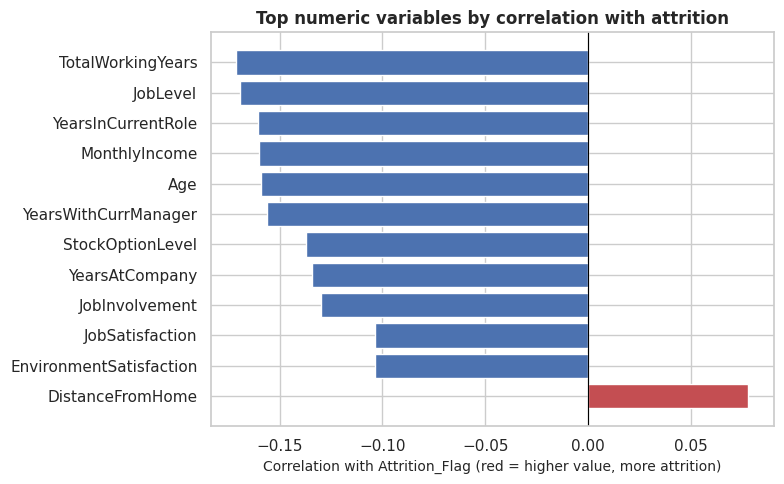

In [22]:
numeric_for_corr = df.select_dtypes(include="number").drop(columns=["EmployeeNumber"])
corr_with_target = (numeric_for_corr.corr()["Attrition_Flag"].drop("Attrition_Flag")
                    .sort_values(key=np.abs, ascending=False).head(12))

fig, ax = plt.subplots(figsize=(8, 5))
colors = [C_LEFT if v > 0 else C_STAY for v in corr_with_target.values]
ax.barh(corr_with_target.index, corr_with_target.values, color=colors)
ax.invert_yaxis(); ax.axvline(0, color="black", lw=0.8)
ax.set_title("Top numeric variables by correlation with attrition")
ax.set_xlabel("Correlation with Attrition_Flag (red = higher value, more attrition)")
plt.tight_layout(); plt.show()

**Reading the chart:** a negative bar (blue) means higher values of that variable go with *lower* attrition (for example longer tenure or higher income); a positive bar (red) means higher values go with *higher* attrition. The correlations are modest in size; many factors act together, which is why a multi-variable model is also built.

In [23]:
seg_cols = ["Department", "JobRole", "OverTime", "BusinessTravel", "MaritalStatus", "AgeGroup",
            "TenureGroup", "IncomeBand", "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance",
            "StockOptionLevel", "JobLevel", "EducationField", "Gender"]
rows = []
for c in seg_cols:
    t = attrition_table(df, c).reset_index()
    t.insert(0, "Attribute", c)
    t = t.rename(columns={c: "Value"})
    rows.append(t)
segments = pd.concat(rows, ignore_index=True)
segments = segments[segments["Employees"] >= 30].copy()
segments["Rate_vs_overall"] = (segments["Attrition_Rate_pct"] / overall_rate).round(2)
top_segments = segments.sort_values("Attrition_Rate_pct", ascending=False).head(12)
print(f"Highest-attrition segments (groups with n>=30). Overall rate = {overall_rate:.1f}%")
display(top_segments[["Attribute", "Value", "Employees", "Left", "Attrition_Rate_pct", "Rate_vs_overall"]].reset_index(drop=True))

lowest = segments.sort_values("Attrition_Rate_pct").head(6)
print("Lowest-attrition segments (n>=30)")
display(lowest[["Attribute", "Value", "Employees", "Left", "Attrition_Rate_pct", "Rate_vs_overall"]].reset_index(drop=True))

Highest-attrition segments (groups with n>=30). Overall rate = 16.1%


,Attribute,Value,Employees,Left,Attrition_Rate_pct,Rate_vs_overall
0,JobRole,Sales Representative,83,33,39.8,2.47
1,AgeGroup,18-25,123,44,35.8,2.22
2,TenureGroup,0-1 yr,215,75,34.9,2.16
3,WorkLifeBalance,1,80,25,31.2,1.94
4,OverTime,Yes,416,127,30.5,1.89
5,IncomeBand,Q1 (lowest),369,108,29.3,1.82
6,JobLevel,1,543,143,26.3,1.63
7,MaritalStatus,Single,470,120,25.5,1.58
8,EnvironmentSatisfaction,1,284,72,25.4,1.58
9,BusinessTravel,Travel_Frequently,277,69,24.9,1.54


Lowest-attrition segments (n>=30)


,Attribute,Value,Employees,Left,Attrition_Rate_pct,Rate_vs_overall
0,JobRole,Research Director,80,2,2.5,0.16
1,JobLevel,4,106,5,4.7,0.29
2,JobRole,Manager,102,5,4.9,0.30
3,TenureGroup,11-20 yrs,180,12,6.7,0.42
4,JobRole,Healthcare Representative,131,9,6.9,0.43
5,JobRole,Manufacturing Director,145,10,6.9,0.43


In [24]:
# Overtime combined with other attributes: does the overtime gap hold across departments?
ot_dept = (df.groupby(["Department", "OverTime"])["Attrition_Flag"].agg(["count", "mean"])
             .rename(columns={"count": "Employees", "mean": "Rate"}).reset_index())
ot_dept["Attrition_Rate_pct"] = (ot_dept["Rate"] * 100).round(1)
display(ot_dept.pivot(index="Department", columns="OverTime", values="Attrition_Rate_pct")
               .rename(columns={"No": "No overtime (%)", "Yes": "Overtime (%)"}))

OverTime,No overtime (%),Overtime (%)
Department,,
Human Resources,15.2,29.4
Research & Development,8.6,27.3
Sales,13.8,37.5


## 14. Feature Preparation and Encoding

**Target:** `Attrition_Flag` (1 = left, 0 = stayed), created from the actual `Attrition` column.

**Removed from the features, to prevent leakage and noise:**

* `Attrition` and `Attrition_Flag` - they *are* the target.
* `EmployeeNumber` - an identifier with no behavioural meaning.
* `AgeGroup`, `TenureGroup`, `IncomeBand` - derived (binned) copies of other features, kept only for EDA.
* Constant columns were already removed in Section 9.

No remaining column is calculated from the outcome. Note that in real life, tenure-type fields must be recorded **before** the prediction date; here the dataset is a single snapshot, so results are exploratory.

**Encoding:** text columns are one-hot encoded (unknown categories ignored); numeric columns, including the ordered 1-4 rating scales, are standardized. All preprocessing is placed inside a scikit-learn `Pipeline`, so scaling and encoding are learned **only from the training data** (no information leaks from the test set).

**Split:** 80% training / 20% test, **stratified** so both sets keep the same attrition ratio.

In [25]:
TARGET = "Attrition_Flag"
NOT_FEATURES = ["EmployeeNumber", "Attrition", "Attrition_Flag", "AgeGroup", "TenureGroup", "IncomeBand"]

X = df.drop(columns=NOT_FEATURES)
y = df[TARGET]

cat_features = X.select_dtypes(exclude="number").columns.tolist()
num_features = X.select_dtypes(include="number").columns.tolist()
print(f"{X.shape[1]} features -> {len(cat_features)} categorical, {len(num_features)} numeric")
print("Categorical:", cat_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "Rows": [len(X_train), len(X_test)],
    "Left (1)": [int(y_train.sum()), int(y_test.sum())],
    "Attrition rate %": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)]},
    index=["Training set", "Test set"])
display(split_summary)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

30 features -> 7 categorical, 23 numeric
Categorical: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


,Rows,Left (1),Attrition rate %
Training set,1176,190,16.2
Test set,294,47,16.0


## 15. Machine-Learning Model Training

**Class imbalance.** Only a minority of employees left, so a model that always predicts "stayed" would still look accurate. To handle this we:

* use **`class_weight`** (balanced) so that mistakes on the minority class (leavers) cost more during training. This is simple, needs no extra library, creates no artificial records, and is applied only to training data;
* evaluate with **recall, precision, F1-score and ROC-AUC** rather than accuracy alone.

**Models compared**

| Model | Purpose |
|---|---|
| Baseline (`DummyClassifier`, always predicts the majority class) | Minimum benchmark - any useful model must beat it |
| Logistic Regression (balanced) | Simple, interpretable linear model |
| Random Forest (balanced) | Non-linear model that can capture interactions |

The model used for final reporting is chosen using **5-fold stratified cross-validation on the training set only** (ROC-AUC), so the test set remains an untouched, honest check.

In [26]:
models = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                            random_state=RANDOM_STATE, n_jobs=-1),
}
pipelines = {name: Pipeline([("prep", preprocessor), ("model", m)]) for name, m in models.items()}

# Cross-validation on the TRAINING data only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_results[name] = (scores.mean(), scores.std())
cv_table = pd.DataFrame(cv_results, index=["CV ROC-AUC mean", "CV ROC-AUC std"]).T.round(3)
display(cv_table)

# Fit every pipeline on the training set
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)

candidate_names = [n for n in pipelines if not n.startswith("Baseline")]
best_name = max(candidate_names, key=lambda n: cv_results[n][0])
best_pipe = pipelines[best_name]
print(f"\nModel selected using cross-validation on the training set: {best_name}")

,CV ROC-AUC mean,CV ROC-AUC std
Baseline (majority class),0.500,0.000
Logistic Regression,0.827,0.028
Random Forest,0.813,0.035



Model selected using cross-validation on the training set: Logistic Regression


## 16. Model Evaluation and Interpretation

All numbers below are measured on the **held-out test set** (employees the model never saw during training).

* **Precision** - of the employees the model flags as likely to leave, what share actually left?
* **Recall** - of the employees who actually left, what share did the model flag?
* **F1-score** - balance of precision and recall.
* **ROC-AUC** - how well the model ranks leavers above stayers (0.5 = no better than chance, 1.0 = perfect).

In [27]:
rows = []
for name, pipe in pipelines.items():
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred, zero_division=0),
                 "F1-score": f1_score(y_test, pred, zero_division=0),
                 "ROC-AUC": roc_auc_score(y_test, proba)})
metrics = pd.DataFrame(rows).set_index("Model").round(3)
display(metrics)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Baseline (majority class),0.840,0.000,0.000,0.000,0.500
Logistic Regression,0.752,0.349,0.638,0.451,0.803
Random Forest,0.840,0.500,0.234,0.319,0.786


**Interpretation.** The baseline reaches a high *accuracy* only because most employees stayed, but its recall is zero - it never finds a single leaver. The comparison table therefore shows why accuracy alone is misleading for imbalanced data. Compare precision, recall, F1 and ROC-AUC across models to see the real improvement over the baseline.

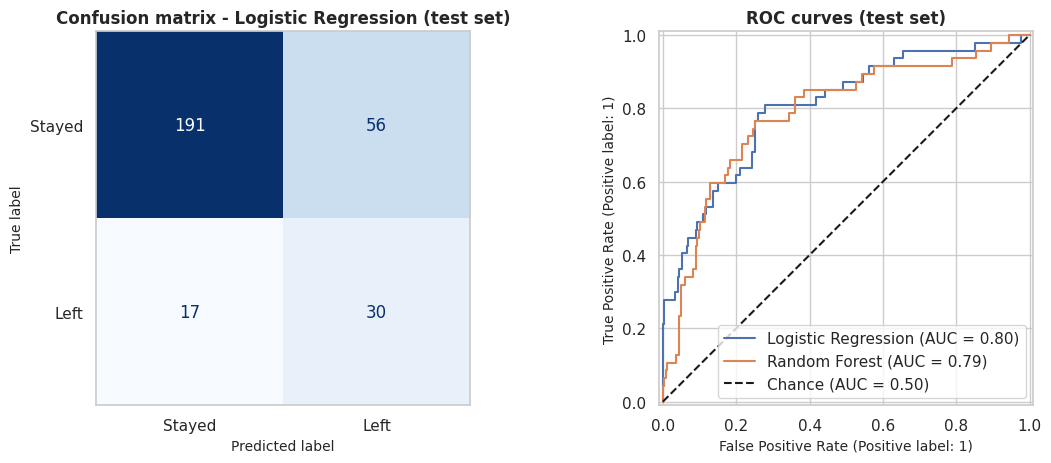

              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294




**Reading the confusion matrix for Logistic Regression:**

* **True negatives = 191** - correctly identified as staying.
* **True positives = 30** - correctly flagged leavers.
* **False positives = 56** - employees flagged as at-risk who actually stayed. *Practical meaning:* HR would spend time on retention conversations that were not strictly necessary; the main risk is wasted effort and employees feeling singled out.
* **False negatives = 17** - employees who left but were not flagged. *Practical meaning:* missed chances to intervene; these are the costly mistakes if the goal is retention.

Which error matters more is a business decision: a low-cost, supportive intervention (such as a check-in) justifies tolerating more false positives to catch more leavers.


In [28]:
best_pred = best_pipe.predict(X_test)
best_proba = best_pipe.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, best_pred)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Left"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title(f"Confusion matrix - {best_name} (test set)")
axes[0].grid(False)
for name, pipe in pipelines.items():
    if name.startswith("Baseline"):
        continue
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=axes[1], name=name)
axes[1].plot([0, 1], [0, 1], "k--", label="Chance (AUC = 0.50)")
axes[1].set_title("ROC curves (test set)"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

print(classification_report(y_test, best_pred, target_names=["Stayed", "Left"], zero_division=0))
display(Markdown(f"""
**Reading the confusion matrix for {best_name}:**

* **True negatives = {tn}** - correctly identified as staying.
* **True positives = {tp}** - correctly flagged leavers.
* **False positives = {fp}** - employees flagged as at-risk who actually stayed. *Practical meaning:* HR would spend time on retention conversations that were not strictly necessary; the main risk is wasted effort and employees feeling singled out.
* **False negatives = {fn}** - employees who left but were not flagged. *Practical meaning:* missed chances to intervene; these are the costly mistakes if the goal is retention.

Which error matters more is a business decision: a low-cost, supportive intervention (such as a check-in) justifies tolerating more false positives to catch more leavers.
"""))

In [29]:
# Trade-off between precision and recall at different decision thresholds (best model, test set)
thr_rows = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (best_proba >= t).astype(int)
    thr_rows.append({"Threshold": t, "Flagged employees": int(p.sum()),
                     "Precision": precision_score(y_test, p, zero_division=0),
                     "Recall": recall_score(y_test, p, zero_division=0),
                     "F1-score": f1_score(y_test, p, zero_division=0)})
display(pd.DataFrame(thr_rows).set_index("Threshold").round(3))

,Flagged employees,Precision,Recall,F1-score
Threshold,,,,
0.2,179,0.235,0.894,0.372
0.3,134,0.284,0.809,0.420
0.4,106,0.349,0.787,0.484
0.5,86,0.349,0.638,0.451
0.6,62,0.435,0.574,0.495
0.7,41,0.512,0.447,0.477


**Why this matters:** lowering the threshold flags more employees and finds more leavers (higher recall) but with more false alarms (lower precision). HR can pick a threshold that matches the capacity and cost of its retention actions. The default threshold of 0.5 is used for the headline metrics above.

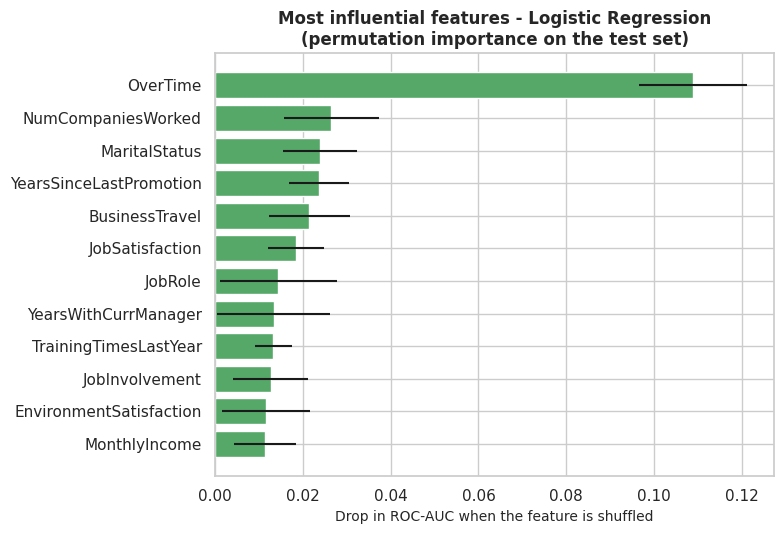

,Feature,Importance,Std
0,OverTime,0.1089,0.0123
1,NumCompaniesWorked,0.0265,0.0108
2,MaritalStatus,0.0239,0.0084
3,YearsSinceLastPromotion,0.0236,0.0069
4,BusinessTravel,0.0215,0.0091
5,JobSatisfaction,0.0184,0.0064
6,JobRole,0.0144,0.0133
7,YearsWithCurrManager,0.0133,0.0129
8,TrainingTimesLastYear,0.0133,0.0041
9,JobInvolvement,0.0127,0.0086


In [30]:
# Permutation importance: how much does the ROC-AUC drop when one original feature is shuffled?
perm = permutation_importance(best_pipe, X_test, y_test, scoring="roc_auc", n_repeats=15,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"Feature": X_test.columns, "Importance": perm.importances_mean,
                            "Std": perm.importances_std})
                .sort_values("Importance", ascending=False).reset_index(drop=True))

top_n = importance.head(12)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top_n["Feature"], top_n["Importance"], xerr=top_n["Std"], color=C_MAIN)
ax.invert_yaxis()
ax.set_title(f"Most influential features - {best_name}\n(permutation importance on the test set)")
ax.set_xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.tight_layout(); plt.show()
display(top_n.round(4))

**Interpreting feature importance - with care.** Features near the top are the ones the model relied on most to *separate leavers from stayers* in this dataset. This shows **association, not causation**: for example, a feature may be important because it is related to something that was not measured. Features with importance close to zero (or negative) contribute little. With only a few hundred test records and a small number of leavers, the ranking can shift if the data is re-split.

### Dashboard-Style Analytical Summary

The dashboard below combines the KPI summary, attrition distribution, department and job-role comparison, major attrition-related factors and the model performance summary in one view.

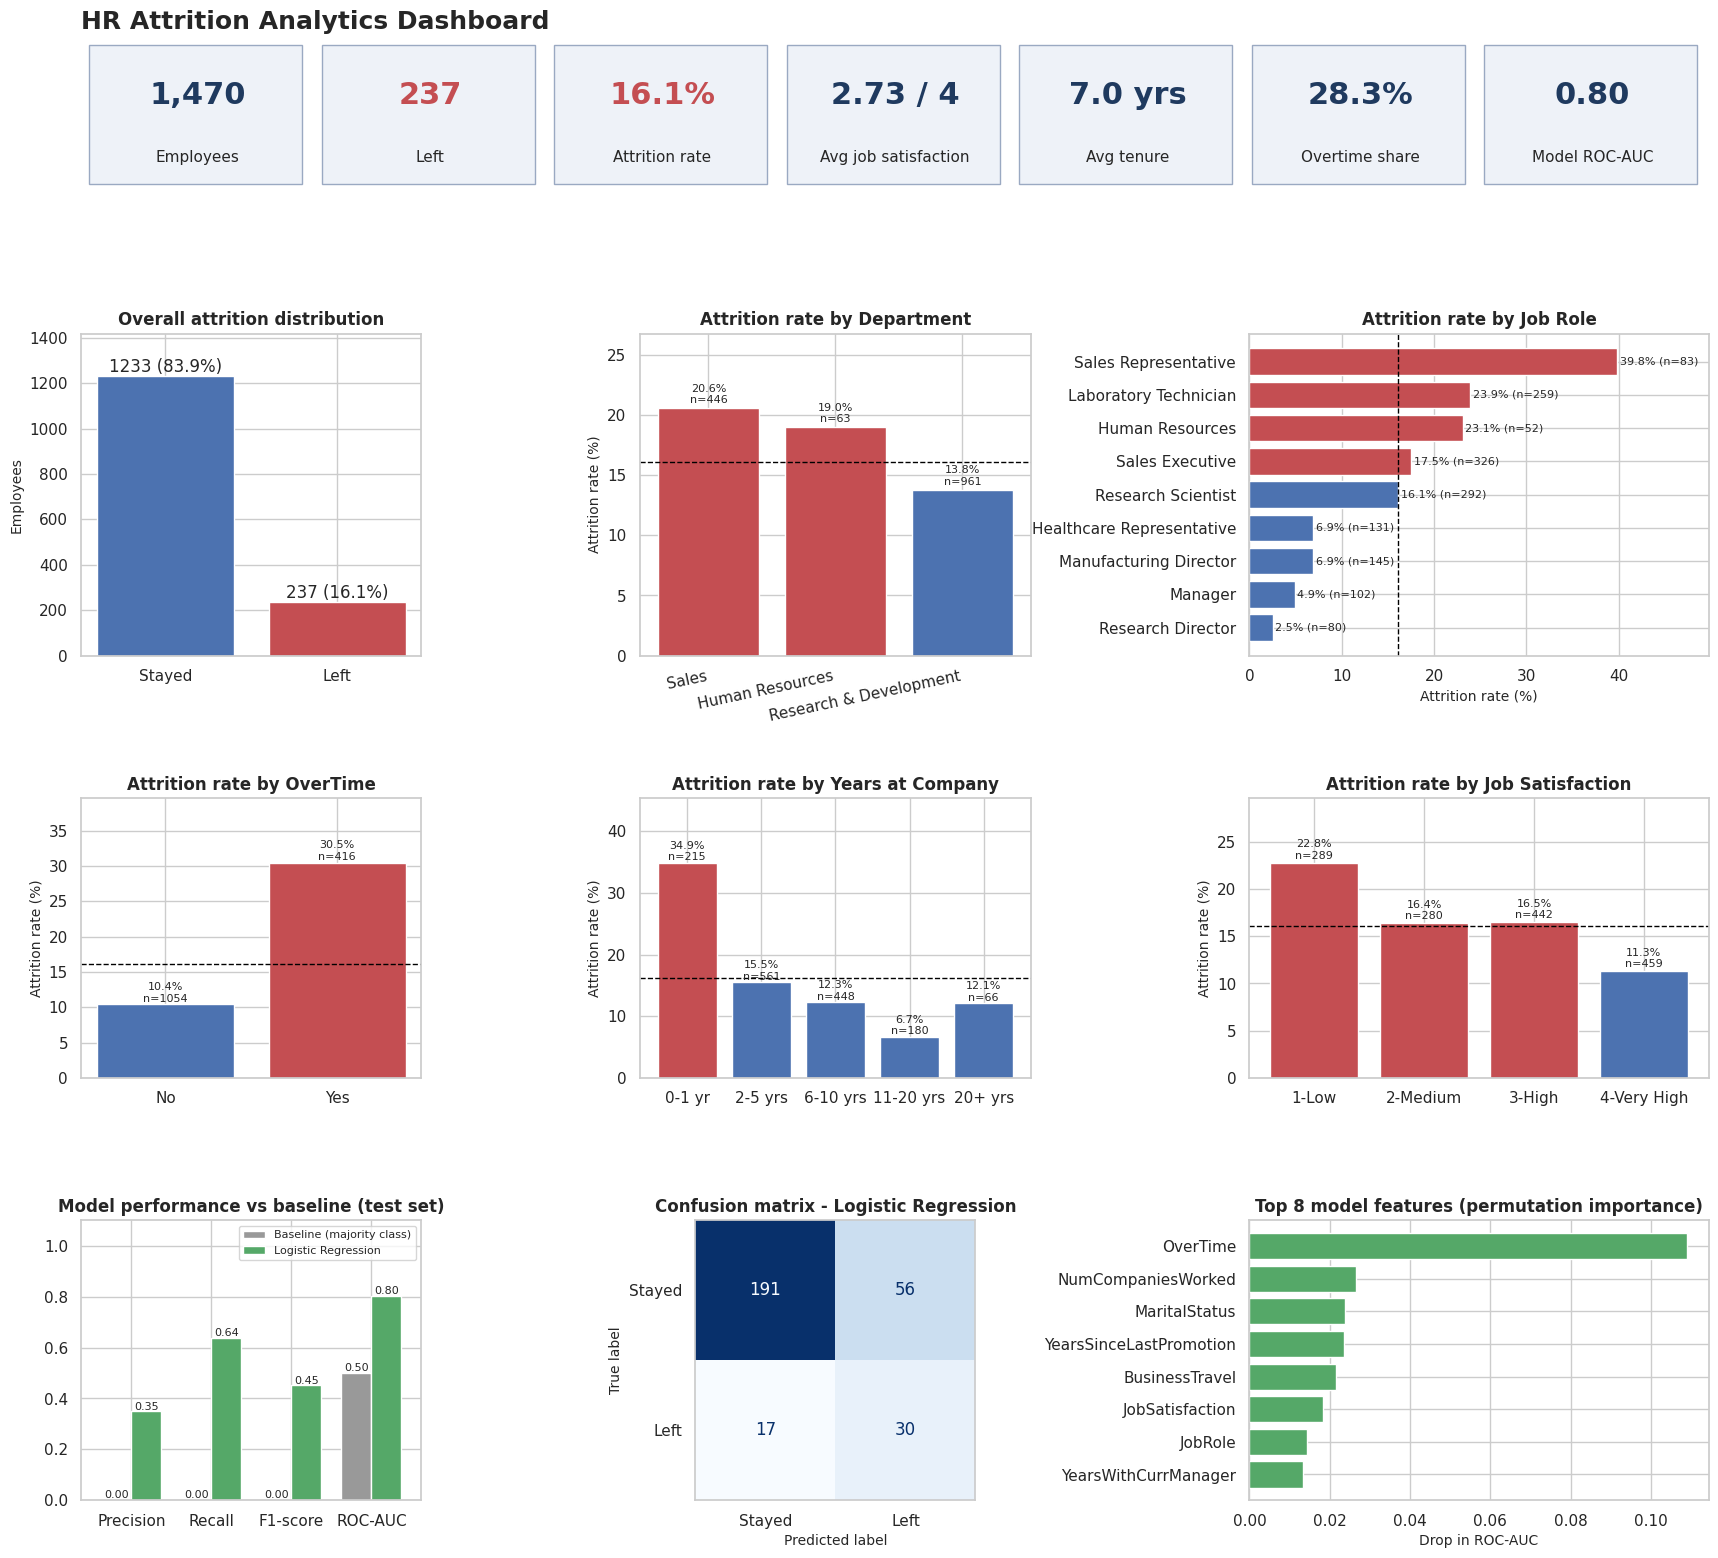

In [31]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(21, 19))
gs = GridSpec(4, 3, figure=fig, height_ratios=[0.55, 1.15, 1.0, 1.0], width_ratios=[1, 1.15, 1.35], hspace=0.55, wspace=0.55)

# --- Row 0: KPI tiles ---
ax = fig.add_subplot(gs[0, :]); ax.axis("off")
tiles = [("Employees", f"{total_emp:,}"), ("Left", f"{left_emp:,}"), ("Attrition rate", f"{overall_rate:.1f}%"),
         ("Avg job satisfaction", f"{df['JobSatisfaction'].mean():.2f} / 4"),
         ("Avg tenure", f"{df['YearsAtCompany'].mean():.1f} yrs"),
         ("Overtime share", f"{(df['OverTime'] == 'Yes').mean() * 100:.1f}%"),
         ("Model ROC-AUC", f"{metrics.loc[best_name, 'ROC-AUC']:.2f}")]
for i, (lab, val) in enumerate(tiles):
    x0 = i / len(tiles)
    ax.add_patch(plt.Rectangle((x0 + 0.005, 0.05), 1 / len(tiles) - 0.012, 0.9, transform=ax.transAxes,
                               facecolor="#EEF2F8", edgecolor="#9AA9C2"))
    ax.text(x0 + 0.5 / len(tiles), 0.62, val, ha="center", va="center", fontsize=22, fontweight="bold",
            color=C_LEFT if lab in ("Attrition rate", "Left") else "#1F3A5F", transform=ax.transAxes)
    ax.text(x0 + 0.5 / len(tiles), 0.22, lab, ha="center", va="center", fontsize=11, transform=ax.transAxes)
ax.set_title("HR Attrition Analytics Dashboard", fontsize=18, fontweight="bold", loc="left")

# --- Row 1: distribution, department, job role ---
a = fig.add_subplot(gs[1, 0])
a.bar(["Stayed", "Left"], counts.values, color=[C_STAY, C_LEFT])
for i, v in enumerate(counts.values):
    a.text(i, v + 15, f"{v} ({v / total_emp * 100:.1f}%)", ha="center")
a.set_title("Overall attrition distribution"); a.set_ylabel("Employees"); a.set_ylim(0, counts.max() * 1.15)
rate_barplot(fig.add_subplot(gs[1, 1]), dept_tbl, "Attrition rate by Department", rotate=12)
rate_barplot(fig.add_subplot(gs[1, 2]), role_tbl, "Attrition rate by Job Role", horizontal=True)

# --- Row 2: overtime, tenure, job satisfaction ---
rate_barplot(fig.add_subplot(gs[2, 0]), attrition_table(df, "OverTime"), "Attrition rate by OverTime")
rate_barplot(fig.add_subplot(gs[2, 1]), attrition_table(df, "TenureGroup"), "Attrition rate by Years at Company")
js = attrition_table(df, "JobSatisfaction"); js.index = [SAT_LABELS[i] for i in js.index]
rate_barplot(fig.add_subplot(gs[2, 2]), js, "Attrition rate by Job Satisfaction")

# --- Row 3: model metrics, confusion matrix, feature importance ---
a = fig.add_subplot(gs[3, 0])
mm = metrics.loc[["Baseline (majority class)", best_name], ["Precision", "Recall", "F1-score", "ROC-AUC"]].T
mm.plot(kind="bar", ax=a, color=["#999999", C_MAIN], rot=0, width=0.75)
a.set_ylim(0, 1.1); a.set_title("Model performance vs baseline (test set)"); a.legend(fontsize=8, loc="upper right")
for cont in a.containers:
    a.bar_label(cont, fmt="%.2f", fontsize=8)
a = fig.add_subplot(gs[3, 1])
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Left"]).plot(ax=a, cmap="Blues", colorbar=False, values_format="d")
a.set_title(f"Confusion matrix - {best_name}"); a.grid(False)
a = fig.add_subplot(gs[3, 2])
t8 = importance.head(8)
a.barh(t8["Feature"], t8["Importance"], color=C_MAIN); a.invert_yaxis()
a.set_title("Top 8 model features (permutation importance)"); a.set_xlabel("Drop in ROC-AUC")
plt.show()

In [32]:
# Dashboard text summary: key findings, calculated from the data
def rate_of(tbl, key):
    return float(tbl.loc[key, "Attrition_Rate_pct"])

age_tbl = attrition_table(df, "AgeGroup")
ten_tbl = attrition_table(df, "TenureGroup")
inc_tbl = attrition_table(df, "IncomeBand")
sat_tbl = attrition_table(df, "JobSatisfaction")
mar_tbl = attrition_table(df, "MaritalStatus")
trv_tbl = attrition_table(df, "BusinessTravel")
stk_tbl = attrition_table(df, "StockOptionLevel")
env_tbl = attrition_table(df, "EnvironmentSatisfaction")
wlb_tbl = attrition_table(df, "WorkLifeBalance")

top_dept, low_dept = dept_tbl.index[0], dept_tbl.index[-1]
big_roles = role_tbl[role_tbl["Employees"] >= 30]
top_role, low_role = big_roles.index[0], big_roles.index[-1]
ot_yes, ot_no = rate_of(ot_tbl, "Yes"), rate_of(ot_tbl, "No")

display(Markdown(f"""
#### Key findings (calculated from the data)

* **Overall:** {left_emp} of {total_emp} employees left - an attrition rate of **{overall_rate:.1f}%**.
* **Department:** highest in **{top_dept}** ({rate_of(dept_tbl, top_dept):.1f}%), lowest in **{low_dept}** ({rate_of(dept_tbl, low_dept):.1f}%).
* **Job role:** highest in **{top_role}** ({rate_of(role_tbl, top_role):.1f}%, n={int(role_tbl.loc[top_role, 'Employees'])}); lowest in **{low_role}** ({rate_of(role_tbl, low_role):.1f}%, n={int(role_tbl.loc[low_role, 'Employees'])}).
* **Overtime:** employees working overtime left at **{ot_yes:.1f}%** versus **{ot_no:.1f}%** for those who did not (about **{ot_yes / ot_no:.1f}x** higher).
* **Tenure:** attrition is **{rate_of(ten_tbl, '0-1 yr'):.1f}%** in the first year or less, versus **{rate_of(ten_tbl, '11-20 yrs'):.1f}%** for 11-20 years.
* **Age:** **{rate_of(age_tbl, '18-25'):.1f}%** for ages 18-25 versus **{rate_of(age_tbl, '46-55'):.1f}%** for ages 46-55.
* **Income:** lowest income quartile **{rate_of(inc_tbl, 'Q1 (lowest)'):.1f}%** versus highest quartile **{rate_of(inc_tbl, 'Q4 (highest)'):.1f}%**.
* **Job satisfaction:** rating 1 (low) **{rate_of(sat_tbl, 1):.1f}%** versus rating 4 (very high) **{rate_of(sat_tbl, 4):.1f}%**.
* **Marital status:** single **{rate_of(mar_tbl, 'Single'):.1f}%**, married **{rate_of(mar_tbl, 'Married'):.1f}%**, divorced **{rate_of(mar_tbl, 'Divorced'):.1f}%**.
* **Business travel:** frequent travellers **{rate_of(trv_tbl, 'Travel_Frequently'):.1f}%** versus non-travellers **{rate_of(trv_tbl, 'Non-Travel'):.1f}%**.
* **Stock options:** level 0 **{rate_of(stk_tbl, 0):.1f}%** versus level 1 **{rate_of(stk_tbl, 1):.1f}%**.
* **Model ({best_name}, test set):** precision **{metrics.loc[best_name, 'Precision']:.2f}**, recall **{metrics.loc[best_name, 'Recall']:.2f}**, F1 **{metrics.loc[best_name, 'F1-score']:.2f}**, ROC-AUC **{metrics.loc[best_name, 'ROC-AUC']:.2f}** (baseline recall = {metrics.loc['Baseline (majority class)', 'Recall']:.2f}).
* **Top model features:** {", ".join(importance.head(5)["Feature"])}.
"""))


#### Key findings (calculated from the data)

* **Overall:** 237 of 1470 employees left - an attrition rate of **16.1%**.
* **Department:** highest in **Sales** (20.6%), lowest in **Research & Development** (13.8%).
* **Job role:** highest in **Sales Representative** (39.8%, n=83); lowest in **Research Director** (2.5%, n=80).
* **Overtime:** employees working overtime left at **30.5%** versus **10.4%** for those who did not (about **2.9x** higher).
* **Tenure:** attrition is **34.9%** in the first year or less, versus **6.7%** for 11-20 years.
* **Age:** **35.8%** for ages 18-25 versus **11.5%** for ages 46-55.
* **Income:** lowest income quartile **29.3%** versus highest quartile **10.3%**.
* **Job satisfaction:** rating 1 (low) **22.8%** versus rating 4 (very high) **11.3%**.
* **Marital status:** single **25.5%**, married **12.5%**, divorced **10.1%**.
* **Business travel:** frequent travellers **24.9%** versus non-travellers **8.0%**.
* **Stock options:** level 0 **24.4%** versus level 1 **9.4%**.
* **Model (Logistic Regression, test set):** precision **0.35**, recall **0.64**, F1 **0.45**, ROC-AUC **0.80** (baseline recall = 0.00).
* **Top model features:** OverTime, NumCompaniesWorked, MaritalStatus, YearsSinceLastPromotion, BusinessTravel.


## 17. Business Insights, Risks and Opportunities

The table below follows the framework **Data → Information → Insights → Decisions → Actions**. All numbers are calculated live from the dataset by the code cell, so they always match the data in your CSV.

In [33]:
tn_, fp_, fn_, tp_ = tn, fp, fn, tp
display(Markdown(f"""
| Stage | Content |
|---|---|
| **Data** (facts) | {total_emp} employee records; {left_emp} left ({overall_rate:.1f}%). No missing values or duplicate records were found. |
| **Information** (facts) | Overtime: {ot_yes:.1f}% vs {ot_no:.1f}% attrition. First-year employees: {rate_of(ten_tbl, '0-1 yr'):.1f}%. Ages 18-25: {rate_of(age_tbl, '18-25'):.1f}%. Lowest income quartile: {rate_of(inc_tbl, 'Q1 (lowest)'):.1f}%. {top_role}: {rate_of(role_tbl, top_role):.1f}%. |
| **Insights** (what it may mean) | Attrition is concentrated, not uniform: it is far higher among overtime workers, early-career and early-tenure employees, lower-paid employees and sales-related and laboratory roles. The overtime gap appears in every department, so it is not just a department effect. |
| **Decisions** (what HR could decide) | Where to focus limited retention effort; whether workload / overtime practices need review; whether early-career support and pay progression need strengthening. |
| **Actions** | See Section 18. |

**Risks (what could go wrong or needs investigation)**

* **Workload risk:** employees working overtime ({int(ot_tbl.loc['Yes', 'Employees'])} people, {int(ot_tbl.loc['Yes', 'Left'])} leavers) carry a much higher attrition rate; burnout may be a factor, but the dataset cannot confirm the reason.
* **Early-career risk:** {int(ten_tbl.loc['0-1 yr', 'Left'])} of {int(ten_tbl.loc['0-1 yr', 'Employees'])} employees with 0-1 year at the company left. Losing people early wastes recruitment and training investment.
* **Concentration risk:** {top_role} ({rate_of(role_tbl, top_role):.1f}%) and the Sales department ({rate_of(dept_tbl, 'Sales'):.1f}%) have the highest attrition; the Human Resources department/role rates are based on small groups (n={int(dept_tbl.loc['Human Resources', 'Employees'])}) and should be read cautiously.
* **Model risk:** at the default threshold the model flagged {tp_ + fp_} employees; {fp_} were false alarms and {fn_} actual leavers were missed. Using it to label individuals could be unfair or inaccurate.
* **Data risk:** the data is a fictional, single-snapshot dataset, so patterns may not transfer to a real organization.

**Opportunities (where improvement may be possible)**

* A lower-attrition benchmark exists inside the organization: Research Director ({rate_of(role_tbl, 'Research Director'):.1f}%), Manager ({rate_of(role_tbl, 'Manager'):.1f}%) and long-tenure groups ({rate_of(ten_tbl, '11-20 yrs'):.1f}%) - HR can study what these groups experience differently.
* Because overtime, travel, pay progression and stock-option eligibility are partly controllable, they are realistic levers for retention experiments.
* The model gives a simple, explainable way to rank *groups* by relative risk for planning (not for individual decisions).
"""))


| Stage | Content |
|---|---|
| **Data** (facts) | 1470 employee records; 237 left (16.1%). No missing values or duplicate records were found. |
| **Information** (facts) | Overtime: 30.5% vs 10.4% attrition. First-year employees: 34.9%. Ages 18-25: 35.8%. Lowest income quartile: 29.3%. Sales Representative: 39.8%. |
| **Insights** (what it may mean) | Attrition is concentrated, not uniform: it is far higher among overtime workers, early-career and early-tenure employees, lower-paid employees and sales-related and laboratory roles. The overtime gap appears in every department, so it is not just a department effect. |
| **Decisions** (what HR could decide) | Where to focus limited retention effort; whether workload / overtime practices need review; whether early-career support and pay progression need strengthening. |
| **Actions** | See Section 18. |

**Risks (what could go wrong or needs investigation)**

* **Workload risk:** employees working overtime (416 people, 127 leavers) carry a much higher attrition rate; burnout may be a factor, but the dataset cannot confirm the reason.
* **Early-career risk:** 75 of 215 employees with 0-1 year at the company left. Losing people early wastes recruitment and training investment.
* **Concentration risk:** Sales Representative (39.8%) and the Sales department (20.6%) have the highest attrition; the Human Resources department/role rates are based on small groups (n=63) and should be read cautiously.
* **Model risk:** at the default threshold the model flagged 86 employees; 56 were false alarms and 17 actual leavers were missed. Using it to label individuals could be unfair or inaccurate.
* **Data risk:** the data is a fictional, single-snapshot dataset, so patterns may not transfer to a real organization.

**Opportunities (where improvement may be possible)**

* A lower-attrition benchmark exists inside the organization: Research Director (2.5%), Manager (4.9%) and long-tenure groups (6.7%) - HR can study what these groups experience differently.
* Because overtime, travel, pay progression and stock-option eligibility are partly controllable, they are realistic levers for retention experiments.
* The model gives a simple, explainable way to rank *groups* by relative risk for planning (not for individual decisions).


## 18. Recommendations for HR Decision-Makers

Each recommendation is tied to evidence from this dataset. Evidence shows **association**, so every recommendation is phrased as something to *review, pilot or investigate*. No cost savings or percentage improvements are claimed, because the dataset contains no cost data.

In [34]:
display(Markdown(f"""
**1. Review overtime and workload practices (highest priority).**  
*Evidence:* attrition is {ot_yes:.1f}% with overtime versus {ot_no:.1f}% without (about {ot_yes / ot_no:.1f}x); the gap appears in all three departments; OverTime is the top feature in the model.  
*Action:* analyse which teams rely most on overtime, review staffing and scheduling, and pilot workload limits or compensatory time off in the highest-overtime teams. Track attrition of the pilot group against similar teams.

**2. Strengthen onboarding and first-year support.**  
*Evidence:* attrition is {rate_of(ten_tbl, '0-1 yr'):.1f}% in the first year, falling to {rate_of(ten_tbl, '2-5 yrs'):.1f}% for 2-5 years and {rate_of(ten_tbl, '11-20 yrs'):.1f}% for 11-20 years; ages 18-25 show {rate_of(age_tbl, '18-25'):.1f}%.  
*Action:* introduce structured onboarding, a mentor or buddy, and 30/90/180-day check-ins; run short exit/stay interviews to learn why early leavers go.

**3. Run a targeted retention review for the highest-attrition roles.**  
*Evidence:* {top_role} {rate_of(role_tbl, top_role):.1f}% (n={int(role_tbl.loc[top_role, 'Employees'])}), Laboratory Technician {rate_of(role_tbl, 'Laboratory Technician'):.1f}%, Sales Executive {rate_of(role_tbl, 'Sales Executive'):.1f}%, versus {rate_of(role_tbl, 'Research Director'):.1f}-{rate_of(role_tbl, 'Manager'):.1f}% for senior roles.  
*Action:* hold focus groups with these roles about targets, workload, travel, pay and career paths, rather than applying one company-wide policy.

**4. Examine pay and career progression for lower-income, entry-level employees.**  
*Evidence:* the lowest income quartile has {rate_of(inc_tbl, 'Q1 (lowest)'):.1f}% attrition versus {rate_of(inc_tbl, 'Q4 (highest)'):.1f}% for the highest; job level 1 and stock option level 0 also show above-average attrition ({rate_of(attrition_table(df, 'JobLevel'), 1):.1f}% and {rate_of(stk_tbl, 0):.1f}%). Income, level and age overlap, so income alone may not be the cause.  
*Action:* benchmark entry-level pay, make promotion criteria transparent, and consider whether wider stock-option eligibility is feasible.

**5. Manage business travel and use satisfaction pulse surveys as early warnings.**  
*Evidence:* frequent travellers {rate_of(trv_tbl, 'Travel_Frequently'):.1f}% versus non-travellers {rate_of(trv_tbl, 'Non-Travel'):.1f}%; low job satisfaction (rating 1) {rate_of(sat_tbl, 1):.1f}% versus {rate_of(sat_tbl, 4):.1f}% at rating 4; low work-life balance (rating 1) {rate_of(wlb_tbl, 1):.1f}% (n={int(wlb_tbl.loc[1, 'Employees'])}).  
*Action:* review travel rotation for frequent travellers and run short quarterly pulse surveys so teams with falling satisfaction can be supported early.

**6. Use the model only as a supporting, aggregate planning aid.**  
*Evidence:* the {best_name} model reached ROC-AUC {metrics.loc[best_name, 'ROC-AUC']:.2f}, recall {metrics.loc[best_name, 'Recall']:.2f} and precision {metrics.loc[best_name, 'Precision']:.2f} on the test set - better than the baseline, but with {fp_} false positives and {fn_} false negatives out of {len(y_test)} test employees.  
*Action:* use model output to prioritise *supportive* conversations and team-level planning; never use it for hiring, firing, promotion or pay decisions; review it regularly for fairness and re-train on current data.
"""))


**1. Review overtime and workload practices (highest priority).**  
*Evidence:* attrition is 30.5% with overtime versus 10.4% without (about 2.9x); the gap appears in all three departments; OverTime is the top feature in the model.  
*Action:* analyse which teams rely most on overtime, review staffing and scheduling, and pilot workload limits or compensatory time off in the highest-overtime teams. Track attrition of the pilot group against similar teams.

**2. Strengthen onboarding and first-year support.**  
*Evidence:* attrition is 34.9% in the first year, falling to 15.5% for 2-5 years and 6.7% for 11-20 years; ages 18-25 show 35.8%.  
*Action:* introduce structured onboarding, a mentor or buddy, and 30/90/180-day check-ins; run short exit/stay interviews to learn why early leavers go.

**3. Run a targeted retention review for the highest-attrition roles.**  
*Evidence:* Sales Representative 39.8% (n=83), Laboratory Technician 23.9%, Sales Executive 17.5%, versus 2.5-4.9% for senior roles.  
*Action:* hold focus groups with these roles about targets, workload, travel, pay and career paths, rather than applying one company-wide policy.

**4. Examine pay and career progression for lower-income, entry-level employees.**  
*Evidence:* the lowest income quartile has 29.3% attrition versus 10.3% for the highest; job level 1 and stock option level 0 also show above-average attrition (26.3% and 24.4%). Income, level and age overlap, so income alone may not be the cause.  
*Action:* benchmark entry-level pay, make promotion criteria transparent, and consider whether wider stock-option eligibility is feasible.

**5. Manage business travel and use satisfaction pulse surveys as early warnings.**  
*Evidence:* frequent travellers 24.9% versus non-travellers 8.0%; low job satisfaction (rating 1) 22.8% versus 11.3% at rating 4; low work-life balance (rating 1) 31.2% (n=80).  
*Action:* review travel rotation for frequent travellers and run short quarterly pulse surveys so teams with falling satisfaction can be supported early.

**6. Use the model only as a supporting, aggregate planning aid.**  
*Evidence:* the Logistic Regression model reached ROC-AUC 0.80, recall 0.64 and precision 0.35 on the test set - better than the baseline, but with 56 false positives and 17 false negatives out of 294 test employees.  
*Action:* use model output to prioritise *supportive* conversations and team-level planning; never use it for hiring, firing, promotion or pay decisions; review it regularly for fairness and re-train on current data.


## 19. Limitations and Ethical Considerations

**Limitations**

* **Fictional, single-snapshot data.** The dataset was created by IBM data scientists for learning; it is not real data and has no time dimension, so we cannot say *when* employees left relative to the recorded values.
* **Association, not causation.** Charts, correlations and feature importance describe patterns; they do not prove that overtime, pay or any other factor *causes* people to leave.
* **Small groups and few leavers.** Only a minority of employees left; the test set holds a small number of leavers (see the confusion matrix), so metrics may change with a different split. Small groups (such as the Human Resources department) give unstable rates.
* **Limited model tuning.** Only two models with default-style settings were compared; the model is a learning exercise and was not extensively tuned or externally validated.
* **Missing context.** Reasons for leaving, labour-market conditions, manager quality and actual costs are not in the data.

**Ethical considerations**

* The model's output is **exploratory** and must **not** be used to make automatic employment decisions or to label individuals.
* The dataset includes sensitive attributes (age, gender, marital status). They were kept for analysis, but decisions based on them could be discriminatory; any real deployment needs a fairness review, legal and privacy compliance, and transparency to employees.
* Predictions can be wrong in both directions; human judgement and a supportive, not punitive, use of results are essential.
* Employee data should be handled with consent, access control and data minimisation.

## 20. Final Conclusion

In [35]:
display(Markdown(f"""
This project converted raw employee records into information, insights and actions. Of **{total_emp}** employees, **{left_emp} ({overall_rate:.1f}%)** left. Attrition was not evenly spread: it was clearly higher for employees working overtime ({ot_yes:.1f}% vs {ot_no:.1f}%), those in their first year ({rate_of(ten_tbl, '0-1 yr'):.1f}%), younger employees, the lowest income quartile, frequent business travellers and sales-related and laboratory roles, led by **{top_role}** ({rate_of(role_tbl, top_role):.1f}%).

A baseline model that always predicts "stayed" finds no leavers (recall {metrics.loc['Baseline (majority class)', 'Recall']:.2f}). The selected **{best_name}** model identified **{tp_} of {tp_ + fn_}** actual leavers in the test set (recall {metrics.loc[best_name, 'Recall']:.2f}) with precision {metrics.loc[best_name, 'Precision']:.2f} and ROC-AUC {metrics.loc[best_name, 'ROC-AUC']:.2f}. This is a useful but imperfect screening signal, and it should be treated as exploratory.

The most practical next steps for HR are to review overtime and workload, strengthen first-year onboarding, run focused retention reviews for the highest-attrition roles, and examine entry-level pay and progression - then measure whether attrition changes. These actions are supported by the evidence above, but cause-and-effect should be tested through pilots before large decisions are made.

*End of notebook.*
"""))


This project converted raw employee records into information, insights and actions. Of **1470** employees, **237 (16.1%)** left. Attrition was not evenly spread: it was clearly higher for employees working overtime (30.5% vs 10.4%), those in their first year (34.9%), younger employees, the lowest income quartile, frequent business travellers and sales-related and laboratory roles, led by **Sales Representative** (39.8%).

A baseline model that always predicts "stayed" finds no leavers (recall 0.00). The selected **Logistic Regression** model identified **30 of 47** actual leavers in the test set (recall 0.64) with precision 0.35 and ROC-AUC 0.80. This is a useful but imperfect screening signal, and it should be treated as exploratory.

The most practical next steps for HR are to review overtime and workload, strengthen first-year onboarding, run focused retention reviews for the highest-attrition roles, and examine entry-level pay and progression - then measure whether attrition changes. These actions are supported by the evidence above, but cause-and-effect should be tested through pilots before large decisions are made.

*End of notebook.*
